# Fake News Detection with DistilBERT
Title-only classification (`label`: 1 = real, 0 = fake) using `distilbert-base-uncased`.

**Colab setup:** Runtime → Change runtime type → **T4 GPU**, then upload `train.tsv` and `test.tsv` (left sidebar → Files) or run the upload cell below.

# 1. Imports and configuration

In [1]:
import os, copy, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch.optim import AdamW
from tqdm.auto import tqdm
from transformers import (DistilBertTokenizerFast, DistilBertForSequenceClassification,
                          get_linear_schedule_with_warmup)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

# ---------------- Config ----------------
MODEL_NAME    = "distilbert-base-uncased"
MAX_LEN       = 64
BATCH_SIZE    = 32
EPOCHS        = 3          # use 2 for a faster run
LEARNING_RATE = 2e-5
WARMUP_RATIO  = 0.1
WEIGHT_DECAY  = 0.01
SEED          = 42
REMOVE_TEST_OVERLAP = True   # drop train/val titles that also appear in the test set

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)

device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"      # mixed precision (fp16) speeds up T4 a lot
print("Device:", device, "| mixed precision:", use_amp)
if device.type == "cpu":
    print("WARNING: no GPU found. Enable it via Runtime > Change runtime type > T4 GPU.")

Device: cuda | mixed precision: True


# 2. Loading the data

In [2]:
# If the files are not already in the Colab working directory, upload them here.
if not (os.path.exists("train.tsv") and os.path.exists("test.tsv")):
    from google.colab import files
    files.upload()   # select train.tsv and test.tsv

train_df = pd.read_csv("train.tsv", sep="\t")
test_df  = pd.read_csv("test.tsv",  sep="\t")
print(train_df.shape, test_df.shape)
train_df.head()

(30000, 6) (8267, 6)


,Unnamed: 0,title,text,subject,date,label
0,2619,Ex-CIA head says Trump remarks on Russia inter...,Former CIA director John Brennan on Friday cri...,politicsNews,"July 22, 2017",1
1,16043,YOU WON’T BELIEVE HIS PUNISHMENT! HISPANIC STO...,How did this man come to OWN this store? There...,Government News,"Jun 19, 2017",0
2,876,Federal Reserve governor Powell's policy views...,President Donald Trump on Thursday tapped Fede...,politicsNews,"November 2, 2017",1
3,19963,SCOUNDREL HILLARY SUPPORTER STARTS “TrumpLeaks...,Hillary Clinton ally David Brock is offering t...,left-news,"Sep 17, 2016",0
4,10783,NANCY PELOSI ARROGANTLY DISMISSES Questions on...,Pleading ignorance is a perfect ploy for Nancy...,politics,"May 26, 2017",0


# 3. Visualizing the data

/tmp/ipykernel_1868/1611415889.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="label", palette="coolwarm", data=train_df, ax=ax[1])


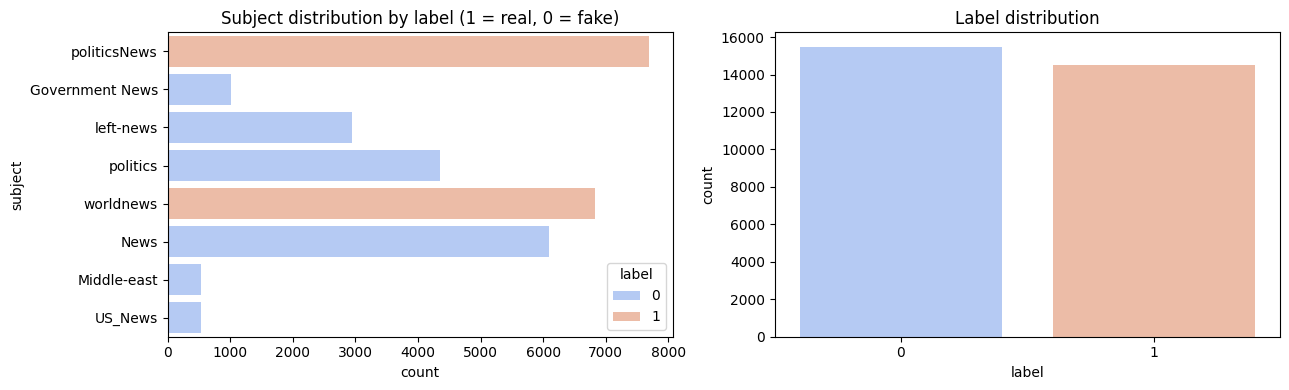

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(y="subject", hue="label", palette="coolwarm", data=train_df, ax=ax[0])
ax[0].set_title("Subject distribution by label (1 = real, 0 = fake)")
sns.countplot(x="label", palette="coolwarm", data=train_df, ax=ax[1])
ax[1].set_title("Label distribution")
plt.tight_layout(); plt.show()

# 4. Preprocessing
Only `title` and `label` are kept. No manual cleaning is needed: DistilBERT's tokenizer handles lowercasing and sub-word splitting itself, and removing stop-words would hurt a pretrained transformer.

In [4]:
train_df = train_df[["title", "label"]].dropna().reset_index(drop=True)
test_df  = test_df[["title", "label"]].dropna().reset_index(drop=True)

# Title length statistics (in words)
title_len = train_df["title"].str.split().str.len()
print("Total number of titles :", len(train_df))
print("Maximum title length   :", title_len.max(), "words")
print("Mean title length      :", round(title_len.mean(), 2), "words")

Total number of titles : 30000
Maximum title length   : 42 words
Mean title length      : 12.42 words


## Checking token lengths against `MAX_LEN`

In [5]:
tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)

sample = train_df["title"].sample(5000, random_state=SEED).tolist()
tok_len = [len(x) for x in tokenizer(sample, add_special_tokens=True)["input_ids"]]
print(f"Titles longer than {MAX_LEN} tokens (would be truncated): {np.mean(np.array(tok_len) > MAX_LEN)*100:.2f}%")
print("95th percentile token length:", int(np.percentile(tok_len, 95)))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Titles longer than 64 tokens (would be truncated): 0.00%
95th percentile token length: 32


## Removing duplicates and train/test overlap
Duplicate titles shared between train and test inflate the score, so they are removed from the training data.

In [6]:
before = len(train_df)
train_df = train_df.drop_duplicates(subset="title").reset_index(drop=True)
print(f"Dropped {before - len(train_df)} duplicate titles inside train")

overlap = train_df["title"].isin(set(test_df["title"]))
print(f"Train titles that also appear in test: {overlap.sum()} ({overlap.mean()*100:.2f}%)")
if REMOVE_TEST_OVERLAP:
    train_df = train_df[~overlap].reset_index(drop=True)
    print("Removed them from train. New train size:", len(train_df))

Dropped 2851 duplicate titles inside train
Train titles that also appear in test: 1497 (5.51%)
Removed them from train. New train size: 25652


# 5. Splitting into training and validation sets

In [7]:
training_df, validation_df = train_test_split(
    train_df, test_size=0.2, random_state=SEED, stratify=train_df["label"])
training_df   = training_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)

print(f"Training set size  : {training_df.shape}")
print(f"Validation set size: {validation_df.shape}")
print(f"Test set size      : {test_df.shape}")

Training set size  : (20521, 2)
Validation set size: (5131, 2)
Test set size      : (8267, 2)


# 6. Tokenization and DataLoaders

In [8]:
def encode(df):
    enc = tokenizer(df["title"].tolist(), truncation=True, padding="max_length",
                    max_length=MAX_LEN, return_tensors="pt")
    labels = torch.tensor(df["label"].values, dtype=torch.long)
    return TensorDataset(enc["input_ids"], enc["attention_mask"], labels)

train_ds = encode(training_df)
val_ds   = encode(validation_df)
test_ds  = encode(test_df)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE * 2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE * 2)

print("Batches per epoch:", len(train_loader))

Batches per epoch: 642


# 7. DistilBERT model

In [9]:
model = DistilBertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

no_decay = ["bias", "LayerNorm.weight"]
param_groups = [
    {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
     "weight_decay": WEIGHT_DECAY},
    {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
     "weight_decay": 0.0},
]
optimizer = AdamW(param_groups, lr=LEARNING_RATE)

total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=int(WARMUP_RATIO * total_steps), num_training_steps=total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f}M | total steps: {total_steps}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parameters: 67.0M | total steps: 1926


# 8. Training
The best epoch (lowest validation loss) is kept automatically, which also guards against the overfitting seen in the CNN-BiLSTM run.

In [10]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    total_loss, all_probs, all_labels = 0.0, [], []
    for ids, mask, labels in loader:
        ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out = model(input_ids=ids, attention_mask=mask, labels=labels)
        total_loss += out.loss.item() * len(labels)
        all_probs.append(torch.softmax(out.logits.float(), dim=-1)[:, 1].cpu().numpy())
        all_labels.append(labels.cpu().numpy())
    probs, labels = np.concatenate(all_probs), np.concatenate(all_labels)
    return total_loss / len(labels), probs, labels

history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_loss, best_state = float("inf"), None
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    running, n = 0.0, 0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")
    for ids, mask, labels in pbar:
        ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            loss = model(input_ids=ids, attention_mask=mask, labels=labels).loss
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        running += loss.item() * len(labels); n += len(labels)
        pbar.set_postfix(loss=f"{running/n:.4f}")

    val_loss, val_probs, val_labels = evaluate(val_loader)
    val_acc = accuracy_score(val_labels, (val_probs > 0.5).astype(int))
    history["train_loss"].append(running / n)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    print(f"Epoch {epoch}: train_loss={running/n:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print("  -> best model so far, checkpoint kept")

model.load_state_dict(best_state)
print(f"\nTraining finished in {(time.time()-start)/60:.1f} minutes")

Epoch 1/3:   0%|          | 0/642 [00:00<?, ?it/s]

Epoch 1: train_loss=0.1697 | val_loss=0.0732 | val_acc=0.9760
  -> best model so far, checkpoint kept


Epoch 2/3:   0%|          | 0/642 [00:00<?, ?it/s]

Epoch 2: train_loss=0.0439 | val_loss=0.0601 | val_acc=0.9825
  -> best model so far, checkpoint kept


Epoch 3/3:   0%|          | 0/642 [00:00<?, ?it/s]

Epoch 3: train_loss=0.0188 | val_loss=0.0568 | val_acc=0.9848
  -> best model so far, checkpoint kept

Training finished in 2.4 minutes


In [ ]:
# =====================================================================
# Save Model Weights & Tokenizer (Executed after the last epoch)
# =====================================================================
import os

OUTPUT_DIR = "distilbert_fake_news"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Save Hugging Face model & tokenizer for Streamlit UI
model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

# 2. Save PyTorch state dictionary checkpoint
torch.save({
    "epoch": EPOCHS,
    "model_state_dict": model.state_dict(),
    "best_val_loss": best_val_loss,
    "history": history
}, os.path.join(OUTPUT_DIR, "distilbert_weights.pt"))

print(f"[SUCCESS] Model weights and tokenizer saved to './{OUTPUT_DIR}'")

# (Google Colab optional) Zip & download model weights:
# !zip -r distilbert_fake_news.zip distilbert_fake_news/
# from google.colab import files; files.download('distilbert_fake_news.zip')


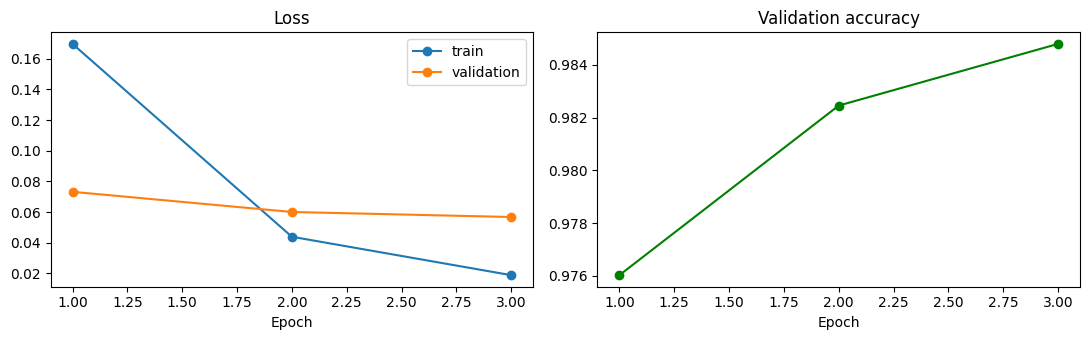

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(range(1, EPOCHS+1), history["train_loss"], marker="o", label="train")
ax[0].plot(range(1, EPOCHS+1), history["val_loss"], marker="o", label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(range(1, EPOCHS+1), history["val_acc"], marker="o", color="green")
ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

# 9. Evaluation on the test set

In [12]:
_, test_probs, y_test = evaluate(test_loader)
test_pred = (test_probs > 0.5).astype(int)

print(f"Model Accuracy      : {accuracy_score(y_test, test_pred):.4f}")
print(f"Model Precision     : {precision_score(y_test, test_pred):.4f}")
print(f"Model Recall        : {recall_score(y_test, test_pred):.4f}")
print(f"Model F1 Score      : {f1_score(y_test, test_pred):.4f}")
print(f"Model ROC AUC Score : {roc_auc_score(y_test, test_probs):.4f}   (computed on probabilities)")
print()
print(classification_report(y_test, test_pred, target_names=["Fake (0)", "Real (1)"], digits=4))

Model Accuracy      : 0.9826
Model Precision     : 0.9755
Model Recall        : 0.9887
Model F1 Score      : 0.9820
Model ROC AUC Score : 0.9987   (computed on probabilities)

              precision    recall  f1-score   support

    Fake (0)     0.9894    0.9769    0.9831      4284
    Real (1)     0.9755    0.9887    0.9820      3983

    accuracy                         0.9826      8267
   macro avg     0.9824    0.9828    0.9826      8267
weighted avg     0.9827    0.9826    0.9826      8267



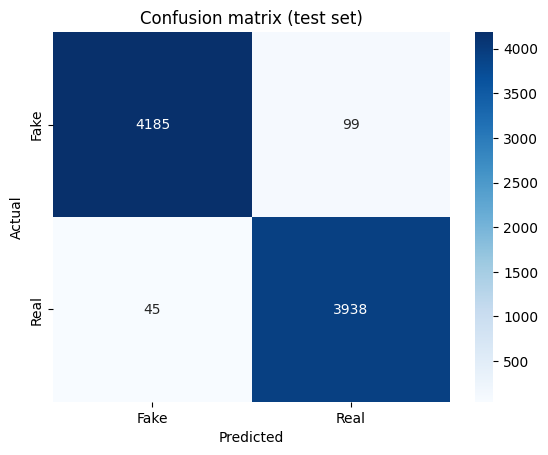

In [13]:
cm = confusion_matrix(y_test, test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fake", "Real"], yticklabels=["Fake", "Real"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test set)")
plt.show()

# 10. Predicting on new headlines and saving the model

In [14]:
@torch.no_grad()
def predict(titles):
    model.eval()
    enc = tokenizer(titles, truncation=True, padding="max_length",
                    max_length=MAX_LEN, return_tensors="pt").to(device)
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
        logits = model(**enc).logits
    probs = torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy()
    return [("REAL" if p > 0.5 else "FAKE", round(float(p), 4)) for p in probs]

examples = [
    "Federal Reserve raises interest rates by a quarter point",
    "YOU WON'T BELIEVE what this celebrity did next!!!",
]
for t, r in zip(examples, predict(examples)):
    print(r, "|", t)

model.save_pretrained("distilbert_fake_news")
tokenizer.save_pretrained("distilbert_fake_news")
print("Saved to ./distilbert_fake_news")

('REAL', 0.9954) | Federal Reserve raises interest rates by a quarter point
('FAKE', 0.001) | YOU WON'T BELIEVE what this celebrity did next!!!


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to ./distilbert_fake_news
